# Model run

In [1]:
# Set scenario name
SCENARIO_NAME = 'temp'
NEW_MT_CENTRES = []

In [2]:
import contextily as ctx
import geopandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from classes.geography_processing import Geoprocessing
from classes.model import Model
from classes.scenario import Scenario
from classes.add_net_benefit import add_net_benefit


In [3]:
hospitals = pd.read_csv('data/stroke_hospitals_2025.csv')

# Get postcode for all hospitals with Use_IVT=1 and Use_MT=0
units_to_test = hospitals['Postcode'][
    ((hospitals['Use_IVT'] == 1) &
     (hospitals['Use_MT'] == 0) &
     (hospitals['Country'] == 'England'))].tolist()


In [4]:
# Run base case model to get baseline net benefit
SCENARIO_NAME = 'Base case'
NEW_MT_CENTRES = []
geo = Geoprocessing(mt_travel_bias = 1, new_mt_centres = NEW_MT_CENTRES)
geo.run()
scenario = Scenario({
        'name': SCENARIO_NAME,
        'limit_to_england' : True
    })
    # Run model
model = Model(
    scenario=scenario,
    geodata=pd.read_csv('processed_data/processed_data.csv'))
model.run()
model_result = model.full_results
model_result = add_net_benefit(model_result)

# Get benefit
base_benefit_by_lsoa = model_result['drip_ship_mrs_0-2_improvement_over_no_treatment']
admissions_by_lsoa = model_result['Admissions_2025_Est']

# Print mean weighted by admissions
print(f"Mean benefit weighted by admissions: {np.average(base_benefit_by_lsoa, weights=admissions_by_lsoa)}")


The input mRS distributions might be improperly labelled.
The input mRS distributions might be improperly labelled.
Mean benefit weighted by admissions: 0.1172283024505532


In [5]:
from IPython.display import clear_output

hospital_net_benefit = {}
hospital_admissions_benefiting = {}
hospital_benefit_for_those_benefitting = {}

for count, unit in enumerate(units_to_test):
    print(f'Running model {count + 1} of {len(units_to_test)}', end='\r')

    geo = Geoprocessing(mt_travel_bias=1, new_mt_centres=[unit])
    geo.run()

    scenario = Scenario({
        'name': SCENARIO_NAME,
        'limit_to_england': True
    })

    model = Model(
        scenario=scenario,
        geodata=pd.read_csv('processed_data/processed_data.csv')
    )
    model.run()

    model_result = add_net_benefit(model.full_results)

    benefit_over_base_by_lsoa = (
        model_result['drip_ship_mrs_0-2_improvement_over_no_treatment']
        - base_benefit_by_lsoa
    )

    total_admissions = admissions_by_lsoa.sum()
    hospital_net_benefit[unit] = (
        np.average(benefit_over_base_by_lsoa, weights=admissions_by_lsoa)
        if total_admissions > 0 else np.nan
    )

    benefiting_lsoas = benefit_over_base_by_lsoa > 0
    benefiting_benefit = benefit_over_base_by_lsoa.loc[benefiting_lsoas]
    benefiting_admissions = admissions_by_lsoa.loc[benefiting_lsoas]

    hospital_admissions_benefiting[unit] = benefiting_admissions.sum()

    benefiting_weight = benefiting_admissions.sum()
    hospital_benefit_for_those_benefitting[unit] = (
        np.average(benefiting_benefit, weights=benefiting_admissions)
        if benefiting_weight > 0 else np.nan
    )

    clear_output(wait=True)

results_df = pd.DataFrame({
    'Hospital': list(hospital_net_benefit),
    'Weighted Net Benefit': list(hospital_net_benefit.values()),
    'Admissions Benefiting': list(hospital_admissions_benefiting.values()),
    'Mean Benefit for Those Benefitting': list(
        hospital_benefit_for_those_benefitting.values()
    )
})

results_df = results_df.sort_values(
    by='Weighted Net Benefit',
    ascending=False
)

hospitals = pd.read_csv('data/stroke_hospitals_2025.csv')
results_df = results_df.merge(
    hospitals[['Postcode', 'SSNAP name', 'Hospital_City']],
    how='left',
    left_on='Hospital',
    right_on='Postcode'
).set_index('SSNAP name')

best_benefit = results_df['Weighted Net Benefit'].max()
results_df['Relative Benefit'] = (
    results_df['Weighted Net Benefit'] / best_benefit
    if pd.notna(best_benefit) and best_benefit != 0 else np.nan
).round(3)

# Express benefit as per 1000 admissions
results_df['Weighted Net Benefit per 1000 Admissions'] = (
    results_df['Weighted Net Benefit'] * 1000
).round(2)
results_df['Mean Benefit for Those Benefitting per 1000 Admissions'] = (
    results_df['Mean Benefit for Those Benefitting'] * 1000
).round(2)

clear_output()
results_df.to_csv('output/benefit_of_each_team.csv', index=True)

results_df.head(20)


,Hospital,Weighted Net Benefit,Admissions Benefiting,Mean Benefit for Those Benefitting,Postcode,Hospital_City,Relative Benefit,Weighted Net Benefit per 1000 Admissions,Mean Benefit for Those Benefitting per 1000 Admissions
SSNAP name,,,,,,,,,
Northwick Park Hospital HASU,HA13UJ,0.000158,6163.58448,0.002330,HA13UJ,Harrow,1.000,0.16,2.33
Musgrove Park Hospital,TA15DA,0.000152,2735.73041,0.005057,TA15DA,Taunton,0.963,0.15,5.06
Royal Devon and Exeter Hospital,EX25DW,0.000150,2680.07615,0.005090,EX25DW,Exeter,0.950,0.15,5.09
Watford General Hospital,WD180HB,0.000148,4980.33041,0.002693,WD180HB,Watford,0.933,0.15,2.69
Luton and Dunstable Hospital,LU40DZ,0.000143,4455.80273,0.002919,LU40DZ,Luton and Dunstable,0.905,0.14,2.92
Frimley Park Hospital,GU167UJ,0.000141,2705.29032,0.004728,GU167UJ,Frimley Park,0.890,0.14,4.73
Northampton General Hospital,NN15BD,0.000138,3457.58664,0.003625,NN15BD,Northampton,0.873,0.14,3.62
Milton Keynes General Hospital,MK65LD,0.000128,2420.14972,0.004812,MK65LD,Milton Keynes,0.811,0.13,4.81
St Peter's Hospital,KT160PZ,0.000122,3320.16967,0.003344,KT160PZ,Chertsey,0.773,0.12,3.34


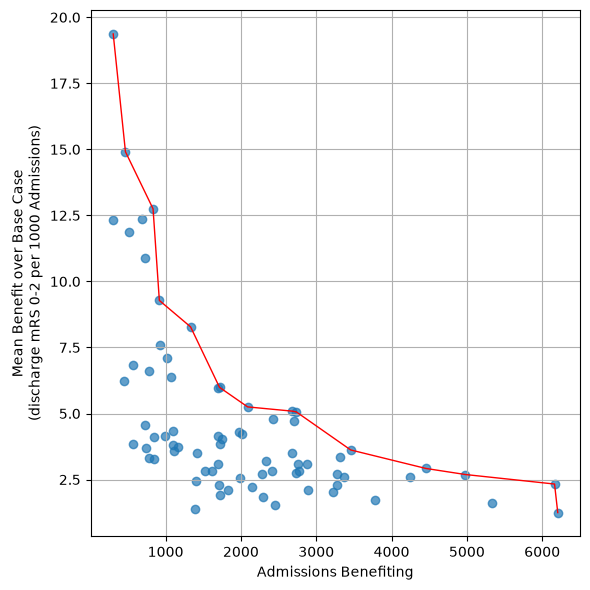

In [17]:
# Plot Mean Benefit for Those Benefitting per 1000 Admissions against Admissions Benefiting

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(1, 1, 1)

ax.scatter(
    results_df['Admissions Benefiting'],
    results_df['Mean Benefit for Those Benefitting per 1000 Admissions'],
    alpha=0.7
)

# Identify Pareto front points - points that are not dominated by any other point
# A point (x, y) is dominated by another point (x', y') if x' >= x and y' >= y
pareto_front = results_df[~results_df.apply(lambda row: any(
    (results_df['Admissions Benefiting'] > row['Admissions Benefiting']) &
    (results_df['Mean Benefit for Those Benefitting per 1000 Admissions'] > row['Mean Benefit for Those Benefitting per 1000 Admissions'])
), axis=1)]

# Plot Pareto front points in a different color
pareto_front_sorted = pareto_front.sort_values('Admissions Benefiting')
ax.plot(
    pareto_front_sorted['Admissions Benefiting'],
    pareto_front_sorted['Mean Benefit for Those Benefitting per 1000 Admissions'],
    color='red',
    linewidth=1
)

ax.grid()

ax.set_xlabel('Admissions Benefiting')
ax.set_ylabel('Mean Benefit over Base Case\n(discharge mRS 0-2 per 1000 Admissions)')

plt.tight_layout()

plt.show()